<a href="https://colab.research.google.com/github/FicaBogdan15/Pneumonia_detection/blob/main/Pneumonia_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pneumonia Detection from Chest X-rays, DenseNet121 baseline

**Independent notebook implementation based on the workflow described in:** Golnaz Hosseini, [*Chest X-ray Pneumonia Detection* (2023)](https://medium.com/artificial-corner/chest-x-ray-pneumonia-detection-65315fd4e186).

**Not a verbatim transcription of the article.** The original approach is preserved (PyTorch, pretrained DenseNet121 with frozen feature extractor, 1-logit classifier, BCEWithLogitsLoss, SGD, 30 epochs), with essential corrections to the dataset splitting, image preprocessing and evaluation.

**Task:** classify chest X-rays as `NORMAL=0` or `PNEUMONIA=1`.

**Dataset structure expected:**
```
chest_xray/
  train/NORMAL/*.jpeg
  train/PNEUMONIA/*.jpeg
  test/NORMAL/*.jpeg
  test/PNEUMONIA/*.jpeg
  val/NORMAL/*.jpeg   # optional; original validation subset is not used
  val/PNEUMONIA/*.jpeg
```

Download from [Kaggle – Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia). This notebook uses the original train/test separation and builds a more useful stratified validation set from train. It does **not** reproduce the article's reduced, artificially balanced 1,000-image subsample.

Run cells from top to bottom. It is an educational experiment, not a medical diagnosis system.

## 1. Imports and setup

The notebook assumes `torch`, `torchvision`, `scikit-learn`, `Pillow`, and `matplotlib` are installed. In Colab, use a GPU runtime when available.

In [ ]:
from pathlib import Path  # Work with dataset file paths.
import copy  # Keep the best model weights in memory.
import random  # Set reproducible random seeds.

import matplotlib.pyplot as plt  # Plot sample images and evaluation charts.
import numpy as np  # Manipulate numeric arrays.
import torch  # Run tensor operations and model training.
from PIL import Image  # Open chest X-ray images.
from sklearn.metrics import (  # Compute classification metrics.
    ConfusionMatrixDisplay, classification_report, confusion_matrix,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split  # Create a validation split.
from torch import nn  # Define the classifier and loss function.
from torch.utils.data import Dataset, DataLoader  # Read images in batches.
from torchvision import models, transforms  # Use DenseNet121 and image transforms.

SEED = 42  # Use the same seed for repeatable experiments.
random.seed(SEED)  # Seed Python random operations.
np.random.seed(SEED)  # Seed NumPy random operations.
torch.manual_seed(SEED)  # Seed PyTorch random operations.
if torch.cuda.is_available():  # Check whether CUDA is available.
    torch.cuda.manual_seed_all(SEED)  # Seed CUDA random operations.

device = torch.device(  # Select the fastest supported computing device.
    "cuda" if torch.cuda.is_available() else
    "mps" if torch.backends.mps.is_available() else "cpu"
)
print("Device:", device)  # Display where the model will run.


Device: cuda


## 2. Download and inspect the dataset

The Kaggle dataset is downloaded automatically with kagglehub. The notebook detects the folder containing train/ and test/, including common nested layouts. The original test split stays untouched.

In [ ]:
import kagglehub  # Download and cache datasets from Kaggle.

download_path = Path(  # Convert the returned folder path into a Path object.
    kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
)
print("Downloaded dataset location:", download_path)  # Show where Kagglehub stored the files.

# Check common folder layouts in Kaggle dataset archives.
candidates = [
    download_path,
    download_path / "chest_xray",
    download_path / "chest_xray" / "chest_xray",
]

DATA_ROOT = next(  # Find the folder that contains both official data splits.
    (folder for folder in candidates
     if (folder / "train" / "NORMAL").is_dir()
     and (folder / "train" / "PNEUMONIA").is_dir()
     and (folder / "test" / "NORMAL").is_dir()
     and (folder / "test" / "PNEUMONIA").is_dir()),
    None,
)
if DATA_ROOT is None:  # Fail early if the downloaded folder layout differs.
    raise FileNotFoundError(
        f"Cannot find train/NORMAL, train/PNEUMONIA, test/NORMAL and test/PNEUMONIA under {download_path}"
    )

TRAIN_ROOT = DATA_ROOT / "train"  # Locate the official training images.
TEST_ROOT = DATA_ROOT / "test"  # Locate the official test images.
print("Dataset root:", DATA_ROOT)  # Confirm the actual folder used for loading.

CLASSES = {"NORMAL": 0, "PNEUMONIA": 1}  # Map folder names to numeric labels.


def collect_images(folder):  # Gather image paths and their class labels.
    paths, labels = [], []  # Create empty result lists.
    for class_name, class_id in CLASSES.items():  # Visit both classes.
        class_folder = folder / class_name  # Locate the current class directory.
        if not class_folder.is_dir():  # Stop if the dataset structure is incorrect.
            raise FileNotFoundError(f"Missing dataset folder: {class_folder}")
        files = sorted(  # Collect common image file types.
            file for file in class_folder.iterdir()
            if file.suffix.lower() in {".jpeg", ".jpg", ".png"}
        )
        paths.extend(files)  # Store the full image paths.
        labels.extend([class_id] * len(files))  # Assign one label per image.
    return paths, labels  # Return matching paths and labels.


train_paths_all, train_labels_all = collect_images(TRAIN_ROOT)  # Load training metadata.
test_paths, test_labels = collect_images(TEST_ROOT)  # Keep the official test set separate.
print("Official training images:", len(train_paths_all))  # Display training size.
print("Official test images:", len(test_paths))  # Display test size.
for class_name, class_id in CLASSES.items():  # Show class distribution.
    print(f"{class_name}: train={train_labels_all.count(class_id)}, test={test_labels.count(class_id)}")


Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Downloaded dataset location: /kaggle/input/chest-xray-pneumonia
Dataset root: /kaggle/input/chest-xray-pneumonia/chest_xray
Official training images: 5216
Official test images: 624
NORMAL: train=1341, test=234
PNEUMONIA: train=3875, test=390


## 3. Create train and validation splits

Only the **original training set** is split. The official test set is reserved for final evaluation.

In [ ]:
train_paths, valid_paths, train_labels, valid_labels = train_test_split(  # Divide train into train and validation.
    train_paths_all, train_labels_all,  # Use only official training samples.
    test_size=0.15,  # Reserve 15% of training images for validation.
    stratify=train_labels_all,  # Keep similar class ratios in both splits.
    random_state=SEED,  # Make the split reproducible.
)
print("Train:", len(train_paths))  # Show training subset size.
print("Validation:", len(valid_paths))  # Show validation subset size.
print("Test:", len(test_paths))  # Show untouched test subset size.
assert not (set(train_paths) & set(valid_paths))  # Check no image path appears in both splits.


Train: 4433
Validation: 783
Test: 624


**Note:** If patient identifiers are available, use a patient-level split instead of only a random stratified split to avoid images from one patient appearing in different subsets.

## 4. Preprocessing and Dataset class

The article converts X-rays to RGB and resizes to 224 × 224. Here, normalization is also added for ImageNet-pretrained DenseNet121. Vertical flipping is omitted because it distorts anatomical orientation.

In [ ]:
WEIGHTS = models.DenseNet121_Weights.DEFAULT  # Select pretrained ImageNet weights.
BATCH_SIZE = 32  # Process 32 images per training batch.

train_transform = transforms.Compose([  # Configure training-time image processing.
    transforms.Resize((224, 224)),  # Convert each image to a consistent size.
    transforms.RandomRotation(degrees=5),  # Apply a small training-only rotation.
    transforms.ToTensor(),  # Convert pixels to a tensor in the [0, 1] range.
    transforms.Normalize(  # Match the pretrained model's expected scale.
        mean=[0.485, 0.456, 0.406],  # Use ImageNet channel means.
        std=[0.229, 0.224, 0.225],  # Use ImageNet channel standard deviations.
    ),
])

valid_transform = transforms.Compose([  # Configure evaluation-time image processing.
    transforms.Resize((224, 224)),  # Use the same image dimensions.
    transforms.ToTensor(),  # Convert image data to a tensor.
    transforms.Normalize(  # Apply the same fixed ImageNet normalization.
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


class ChestXrayDataset(Dataset):  # Build a PyTorch dataset from image paths.
    def __init__(self, paths, labels, transform):  # Receive image paths, labels, and transforms.
        self.paths = paths  # Save the image locations.
        self.labels = labels  # Save the class labels.
        self.transform = transform  # Save preprocessing steps.

    def __len__(self):  # Report the number of images.
        return len(self.paths)

    def __getitem__(self, index):  # Load one sample by index.
        with Image.open(self.paths[index]) as image:  # Open one X-ray file safely.
            image = image.convert("RGB")  # Duplicate grayscale intensities into 3 channels.
        image = self.transform(image)  # Apply the required preprocessing.
        label = torch.tensor(self.labels[index], dtype=torch.float32)  # Create a float label for BCE.
        return image, label  # Return an image tensor and its label.


train_data = ChestXrayDataset(train_paths, train_labels, train_transform)  # Training data.
valid_data = ChestXrayDataset(valid_paths, valid_labels, valid_transform)  # Validation data.
test_data = ChestXrayDataset(test_paths, test_labels, valid_transform)  # Untouched test data.

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)  # Shuffle train batches.
valid_loader = DataLoader(valid_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)  # Keep validation fixed.
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)  # Keep test fixed.

batch_images, batch_labels = next(iter(train_loader))  # Inspect a batch.
print("Image batch:", batch_images.shape)  # Expect [batch, 3, 224, 224].
print("Label batch:", batch_labels.shape)  # Expect [batch].


Image batch: torch.Size([32, 3, 224, 224])
Label batch: torch.Size([32])


## 5. Preview the input images

Reverse normalization **only for display** so that the images look meaningful.

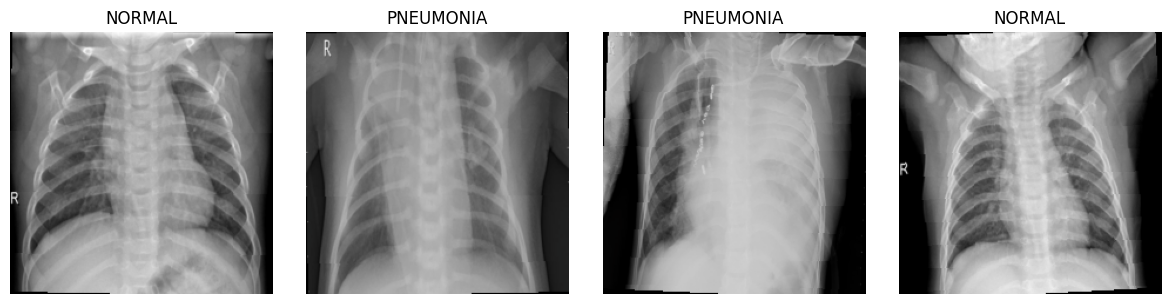

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))  # Create four image panels.
means = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)  # Shape channel means.
stds = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)  # Shape channel standard deviations.
for i, ax in enumerate(axes):  # Show the first four batch examples.
    image = batch_images[i] * stds + means  # Undo normalization for viewing.
    image = image.clamp(0, 1).permute(1, 2, 0)  # Reorder channels for Matplotlib.
    ax.imshow(image)  # Display the reconstructed image.
    ax.set_title("PNEUMONIA" if batch_labels[i].item() == 1 else "NORMAL")  # Show class label.
    ax.axis("off")  # Hide coordinate axes.
plt.tight_layout()  # Improve panel spacing.
plt.show()  # Render the images.


## 6. Build the pretrained DenseNet121 model

Following the article, the pretrained feature extractor is **frozen**, and only the final binary classifier is trained.

In [ ]:
class PneumoniaDenseNet(nn.Module):  # Wrap DenseNet121 in a binary classifier.
    def __init__(self):  # Configure model layers.
        super().__init__()  # Initialize the PyTorch base class.
        self.network = models.densenet121(weights=WEIGHTS)  # Load pretrained DenseNet121.
        for parameter in self.network.features.parameters():  # Visit feature-extractor weights.
            parameter.requires_grad = False  # Prevent updates to pretrained features.
        input_size = self.network.classifier.in_features  # Read the original classifier input size.
        self.network.classifier = nn.Linear(input_size, 1)  # Predict one logit for pneumonia.

    def forward(self, inputs):  # Define how images pass through the network.
        return self.network(inputs).flatten()  # Return one logit per image.


model = PneumoniaDenseNet().to(device)  # Create the model on the chosen device.
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)  # Count trainable weights.
print("Trainable parameters:", trainable)  # Confirm only the classifier is trainable.


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 154MB/s]


Trainable parameters: 1025


## 7. Loss function and optimizer

This cell uses **ordinary BCEWithLogitsLoss**, matching the baseline approach in the article. Weighted BCE is intentionally **not** included in this notebook.

In [ ]:
EPOCHS = 30  # Match the article's training duration.
LEARNING_RATE = 0.01  # Match the article's SGD learning rate.
criterion = nn.BCEWithLogitsLoss()  # Compare binary labels with unnormalized logits.
optimizer = torch.optim.SGD(  # Configure stochastic gradient descent.
    model.network.classifier.parameters(),  # Update only the new classifier.
    lr=LEARNING_RATE,  # Set the optimizer step size.
)


## 8. Training and validation functions

Validation never updates weights. Accuracy is computed by thresholding sigmoid probabilities at 0.5.

In [ ]:
def run_epoch(model, loader, loss_function, optimizer=None):  # Run one train or validation pass.
    training = optimizer is not None  # Detect whether weights should be updated.
    model.train(training)  # Set training or evaluation mode.
    model.network.features.eval()  # Keep frozen BatchNorm running statistics unchanged.
    loss_sum, correct, total = 0.0, 0, 0  # Track loss and predictions.

    for images, labels in loader:  # Read one batch at a time.
        images = images.to(device)  # Move images to GPU, MPS, or CPU.
        labels = labels.to(device)  # Move targets to the same device.
        if training:  # Only reset gradients when training.
            optimizer.zero_grad()  # Clear gradients from the previous batch.

        with torch.set_grad_enabled(training):  # Disable gradients during validation.
            logits = model(images)  # Predict one raw score per image.
            loss = loss_function(logits, labels)  # Measure classification error.
            if training:  # Only optimize during training.
                loss.backward()  # Calculate gradients for trainable parameters.
                optimizer.step()  # Update classifier weights.

        probabilities = torch.sigmoid(logits)  # Convert logits to probabilities.
        predictions = (probabilities >= 0.5).long()  # Apply the binary decision threshold.
        correct += (predictions == labels.long()).sum().item()  # Count correct predictions.
        total += labels.size(0)  # Count processed samples.
        loss_sum += loss.item() * labels.size(0)  # Sum batch losses weighted by batch size.

    return loss_sum / total, correct / total  # Return mean loss and accuracy.


## 9. Train the baseline and save the best checkpoint

The best model is selected using **validation loss**. The original test set is not used for model selection.

In [ ]:
history = {"train_loss": [], "valid_loss": [], "train_acc": [], "valid_acc": []}  # Store learning curves.
best_loss = float("inf")  # Start with no best validation result.
best_weights = copy.deepcopy(model.state_dict())  # Save initial parameters as a fallback.

for epoch in range(EPOCHS):  # Run the requested number of training epochs.
    train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)  # Update the classifier.
    valid_loss, valid_acc = run_epoch(model, valid_loader, criterion)  # Evaluate without updates.
    history["train_loss"].append(train_loss)  # Record training loss.
    history["valid_loss"].append(valid_loss)  # Record validation loss.
    history["train_acc"].append(train_acc)  # Record training accuracy.
    history["valid_acc"].append(valid_acc)  # Record validation accuracy.

    if valid_loss < best_loss:  # Check whether validation improved.
        best_loss = valid_loss  # Update the best validation loss.
        best_weights = copy.deepcopy(model.state_dict())  # Save the new best weights.

    print(  # Print one concise status line per epoch.
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"train loss={train_loss:.4f}, acc={train_acc:.3f} | "
        f"valid loss={valid_loss:.4f}, acc={valid_acc:.3f}"
    )

model.load_state_dict(best_weights)  # Restore the best validation checkpoint.
torch.save(model.state_dict(), "densenet121_baseline.pth")  # Save weights for later use.


Epoch 01/30 | train loss=0.2967, acc=0.883 | valid loss=0.2402, acc=0.894
Epoch 02/30 | train loss=0.1884, acc=0.933 | valid loss=0.2028, acc=0.914
Epoch 03/30 | train loss=0.1657, acc=0.940 | valid loss=0.1908, acc=0.916
Epoch 04/30 | train loss=0.1504, acc=0.946 | valid loss=0.1510, acc=0.941
Epoch 05/30 | train loss=0.1414, acc=0.950 | valid loss=0.1359, acc=0.954
Epoch 06/30 | train loss=0.1347, acc=0.950 | valid loss=0.1344, acc=0.948
Epoch 07/30 | train loss=0.1320, acc=0.952 | valid loss=0.1389, acc=0.945
Epoch 08/30 | train loss=0.1274, acc=0.954 | valid loss=0.1321, acc=0.945
Epoch 09/30 | train loss=0.1251, acc=0.951 | valid loss=0.1261, acc=0.948
Epoch 10/30 | train loss=0.1167, acc=0.957 | valid loss=0.1327, acc=0.948
Epoch 11/30 | train loss=0.1115, acc=0.961 | valid loss=0.1210, acc=0.950
Epoch 12/30 | train loss=0.1112, acc=0.958 | valid loss=0.1130, acc=0.954
Epoch 13/30 | train loss=0.1099, acc=0.961 | valid loss=0.1100, acc=0.958
Epoch 14/30 | train loss=0.1095, acc=0

## 10. Plot training curves

Use these charts to inspect possible overfitting.

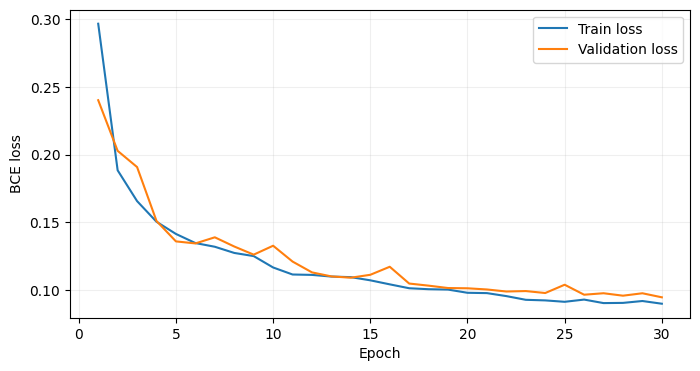

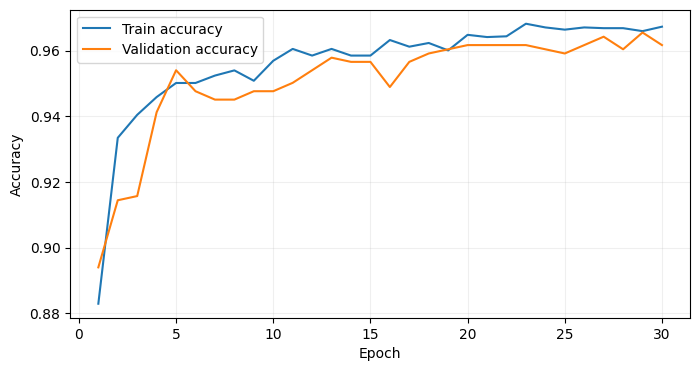

In [ ]:
epochs = range(1, len(history["train_loss"]) + 1)  # Create epoch numbers.
plt.figure(figsize=(8, 4))  # Create the loss chart.
plt.plot(epochs, history["train_loss"], label="Train loss")  # Show training loss.
plt.plot(epochs, history["valid_loss"], label="Validation loss")  # Show validation loss.
plt.xlabel("Epoch")  # Label the horizontal axis.
plt.ylabel("BCE loss")  # Label the vertical axis.
plt.legend()  # Identify each curve.
plt.grid(alpha=0.2)  # Add a light reference grid.
plt.show()  # Display the loss chart.

plt.figure(figsize=(8, 4))  # Create the accuracy chart.
plt.plot(epochs, history["train_acc"], label="Train accuracy")  # Show training accuracy.
plt.plot(epochs, history["valid_acc"], label="Validation accuracy")  # Show validation accuracy.
plt.xlabel("Epoch")  # Label the horizontal axis.
plt.ylabel("Accuracy")  # Label the vertical axis.
plt.legend()  # Identify each curve.
plt.grid(alpha=0.2)  # Add a light reference grid.
plt.show()  # Display the accuracy chart.


## 11. Final evaluation on the test set

Report class-wise metrics and confusion matrix; do not use the test results to select hyperparameters.

              precision    recall  f1-score   support

      NORMAL     0.9737    0.4744    0.6379       234
   PNEUMONIA     0.7588    0.9923    0.8600       390

    accuracy                         0.7981       624
   macro avg     0.8663    0.7333    0.7490       624
weighted avg     0.8394    0.7981    0.7767       624



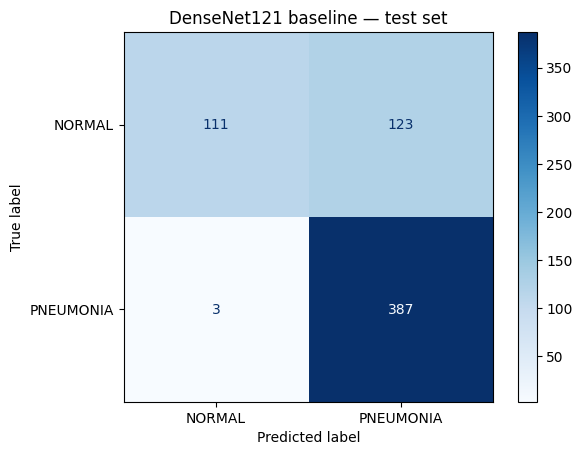

In [ ]:
model.eval()  # Disable training-specific behavior.
all_labels, all_probabilities = [], []  # Collect true labels and predicted probabilities.

with torch.no_grad():  # Skip gradient calculations during final evaluation.
    for images, labels in test_loader:  # Read the official test images.
        logits = model(images.to(device))  # Predict raw pneumonia scores.
        probabilities = torch.sigmoid(logits)  # Convert scores into probabilities.
        all_labels.extend(labels.numpy().astype(int).tolist())  # Store true class labels.
        all_probabilities.extend(probabilities.cpu().numpy().tolist())  # Store predicted probabilities.

all_predictions = [int(p >= 0.5) for p in all_probabilities]  # Convert scores into binary predictions.
print(classification_report(  # Display precision, recall and F1 for both classes.
    all_labels, all_predictions, target_names=["NORMAL", "PNEUMONIA"], digits=4
))

matrix = confusion_matrix(all_labels, all_predictions)  # Count TP, TN, FP and FN.
ConfusionMatrixDisplay(matrix, display_labels=["NORMAL", "PNEUMONIA"]).plot(  # Draw the matrix.
    cmap="Blues", values_format="d"
)
plt.title("DenseNet121 baseline — test set")  # Add a descriptive title.
plt.show()  # Display the matrix.


## 12. ROC curve and ROC-AUC

ROC requires **continuous probabilities**, not only the final 0/1 decisions. This fixes an error in the article.

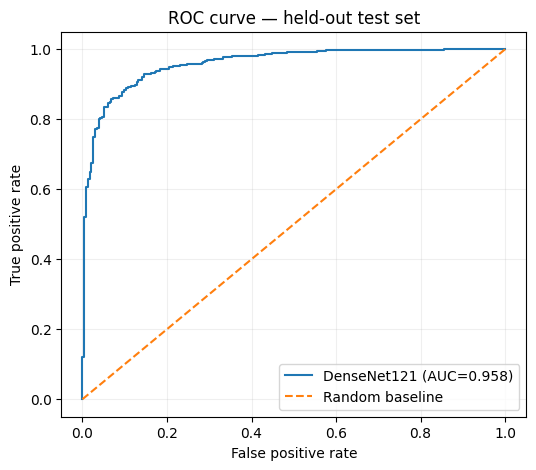

In [ ]:
auc_value = roc_auc_score(all_labels, all_probabilities)  # Calculate ROC-AUC from probabilities.
fpr, tpr, thresholds = roc_curve(all_labels, all_probabilities)  # Measure rates across thresholds.
plt.figure(figsize=(6, 5))  # Create the ROC chart.
plt.plot(fpr, tpr, label=f"DenseNet121 (AUC={auc_value:.3f})")  # Plot the classifier's ROC curve.
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")  # Show random-reference line.
plt.xlabel("False positive rate")  # Label the false-alarm axis.
plt.ylabel("True positive rate")  # Label sensitivity axis.
plt.title("ROC curve — held-out test set")  # Name the plot.
plt.legend()  # Show the AUC value and legend.
plt.grid(alpha=0.2)  # Add a light background grid.
plt.show()  # Display the ROC chart.
